# EGMS kontra niwelacja — zachodnia Nadrenia Północna-Westfalia (Niemcy)

**Pytanie:** czy EGMS pokazuje to samo osiadanie co niwelacja precyzyjna, czyli pomiar wysokości reperów wykonany na ziemi?

**Dane:**
- EGMS L3 Ortho (ruch pionowy w komórkach 100 × 100 m), wydanie 2019–2023,
- niwelacja: rejestr punktów wysokościowych Geobasis NRW; repery z dwoma pomiarami w oknie EGMS (najczęściej maj 2019
  i maj 2022).

**Dlaczego to ważne:** niwelacja nie korzysta z GNSS, a EGMS jest kalibrowany modelem GNSS. To sprawdzenie jest więc
niezależne od kalibracji.

**Jak porównujemy:** dla każdego reperu bierzemy komórkę EGMS, w której leży, i porównujemy zmianę wysokości między
tymi samymi dniami [mm]. Bierzemy wszystkie repery z dwoma pomiarami, bez wybierania według EGMS. Progi oceny
ustaliliśmy przed obliczeniami.

**Jak uruchomić:** menu *Środowisko wykonawcze → Uruchom wszystko* (kilka sekund). Notatnik tylko czyta wyniki z Dysku,
policzone wcześniej w `EGMS_Monitoring.ipynb`. Kod jest ukryty — kliknij tytuł komórki, żeby go zobaczyć.

In [1]:
#@title Przygotowanie: połączenie z Dyskiem i wczytanie wyników
from google.colab import drive
drive.mount('/content/drive')
import json, subprocess, sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, Markdown, HTML
PROJECT_DIR = '/content/drive/MyDrive/GeoWorldLook/egmscheck'
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)
for m in [m for m in sys.modules if m.startswith('step_0')]:
    del sys.modules[m]          # zawsze kod z Dysku: moduł zapamiętany w jądrze sprzed aktualizacji dawał KeyError
from step_05_colab_run import (CHECK_CONFIG, region_paths, levelling_check_paths, _levelling_check_examples,
                               _example_sites, _read_sites, _sources)
rt = {'PROJECT_DIR': PROJECT_DIR}
KOD = subprocess.run(['git', '-C', PROJECT_DIR, 'log', '-1', '--format=%h z %ci'], capture_output=True, text=True).stdout.strip()
print('Wyniki policzone kodem:', KOD)
KROK = ('W EGMS_Monitoring.ipynb uruchom komórki startowe (pobierają aktualny kod na Dysk) i komórki obliczeń tego '
        'przypadku, a potem ten notatnik jeszcze raz.')

def wymagaj(paths, klucze, kolumny=None):
    # Wyniki starsze niż notatnik = jasny komunikat, co uruchomić (zamiast KeyError albo pustej komórki).
    stare = [k for k in klucze if k not in paths]
    if stare:
        raise RuntimeError(f'Kod na Dysku ({KOD}) jest starszy niż ten notatnik (brak: {stare}). {KROK}')
    brak = [Path(paths[k]).name for k in klucze if not Path(paths[k]).exists()]
    if brak:
        raise FileNotFoundError(f'Brak wyników na Dysku: {brak}. {KROK}')
    for k, cols in (kolumny or {}).items():
        jest = pd.read_csv(paths[k], nrows=0).columns
        if [c for c in cols if c not in jest]:
            raise RuntimeError(f'{Path(paths[k]).name} policzony starszym kodem (brak kolumn {[c for c in cols if c not in jest]}). {KROK}')

def pokaz(path, width=850):
    # Brak pliku = błąd (wyniki liczy EGMS_Monitoring.ipynb), nie pusta komórka.
    if not Path(path).exists():
        raise FileNotFoundError(f'Brak {path}: uruchom najpierw notebooks/EGMS_Monitoring.ipynb')
    display(Image(str(path), width=width))

def tabela(df):
    display(HTML(df.to_html(index=False)))

def ocena(x):
    s = str(x)
    return '✔ tak' if s == 'True' else '✘ nie' if s == 'False' else '— nie liczone'

def kryteria(path, kody):
    t = pd.read_csv(path)
    t = t[t['kryterium'].str[:2].isin(kody)]
    return pd.DataFrame({'kod': t['kryterium'].str[:2].to_numpy(), 'Kryterium': t['kryterium'].to_numpy(),
                         'Wynik': t['wynik'].to_numpy(), 'Próg': t['próg'].to_numpy(),
                         'Spełnione': t['spełnione'].map(ocena).to_numpy()})
C = levelling_check_paths(rt, CHECK_CONFIG, 'nrw_west')
wymagaj(C, ['compare', 'summary', 'summary_rel', 'offset_rel', 'groups', 'groups_rel', 'figure', 'map', 'uncertainty'],
        kolumny={'compare': ['sigma_dh_mm']})
strong = CHECK_CONFIG['regions']['nrw_west']['levelling']['strong_motion_mm_yr']
res = pd.read_csv(C['compare'], dtype={'benchmark_id': str})
ok = res[res['status'] == 'ok']
unc = json.loads(C['uncertainty'].read_text())
off = json.loads(C['offset_rel'].read_text())
k = unc['k_sigma']

Mounted at /content/drive
Wyniki policzone kodem: 21905dd z 2026-10-15 11:44:29 +0000


## 1. Gdzie EGMS widzi ruch

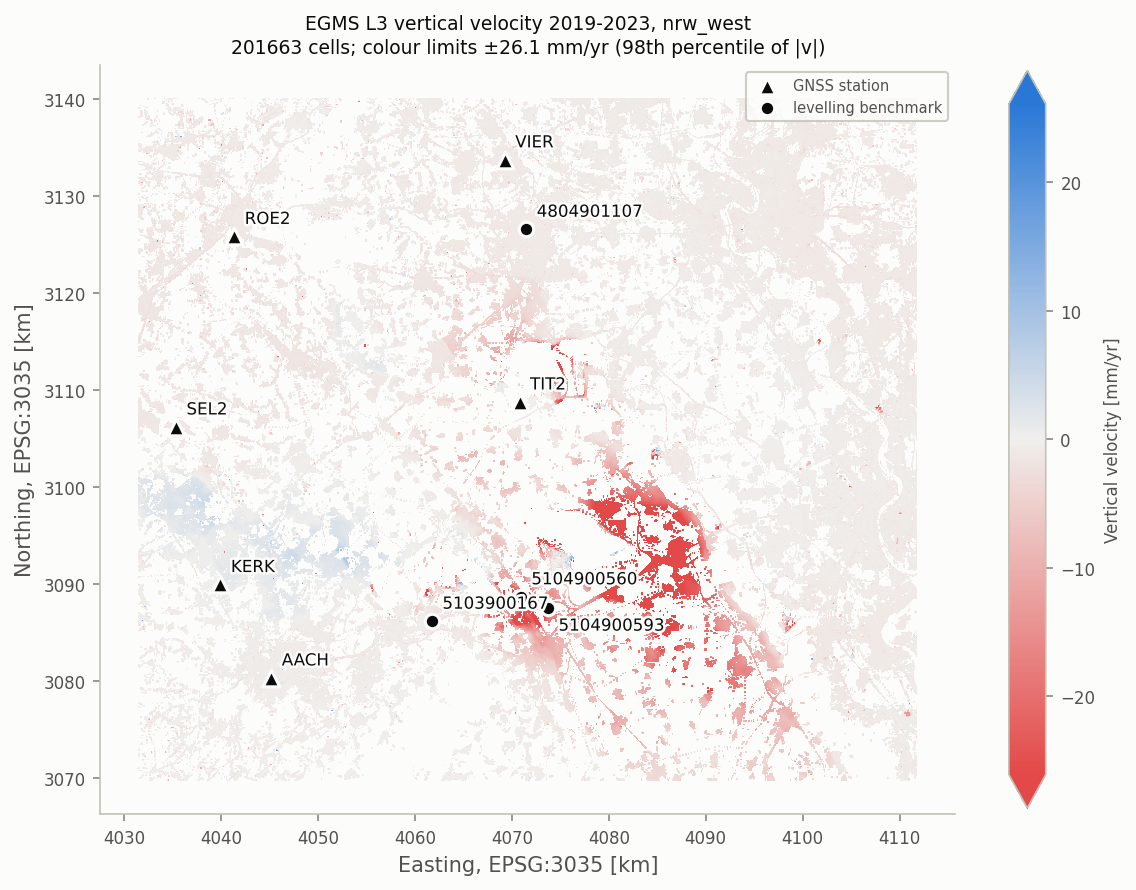

In [2]:
#@title Mapa tempa ruchu pionowego EGMS 2019–2023
pokaz(C['map'], 720)

**Jak czytać:** czerwone plamy to niecki osiadania przy odkrywkach węgla brunatnego (do kilkudziesięciu mm/rok),
niebieskie to wypiętrzanie. Trójkąty to stacje GNSS, kółka to repery pokazane niżej w czasie.

## 2. Czy niwelacja potwierdza ruch z EGMS?

**1216 reperów** z dwoma pomiarami niwelacyjnymi i komórką EGMS. Niepewność EGMS (mediana, ±2σ): **±2.0 mm**; w granicach niepewności: **12%** reperów, a po odjęciu wspólnego przesunięcia (wariant względny) **37%**.

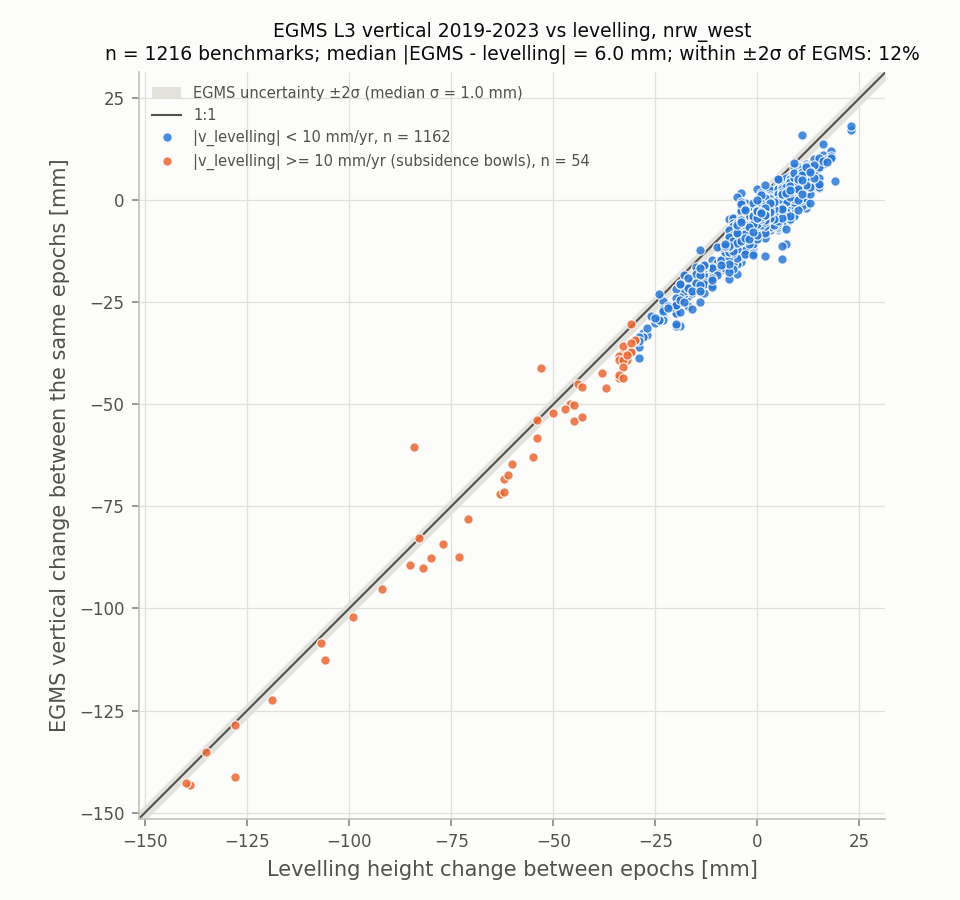

In [3]:
#@title Wykres: zmiana wysokości z niwelacji kontra z EGMS (wszystkie repery)
display(Markdown(f'**{len(ok)} reperów** z dwoma pomiarami niwelacyjnymi i komórką EGMS. '
                 f'Niepewność EGMS (mediana, ±{k:g}σ): **±{k * unc["median_sigma_dh_mm"]:.1f} mm**; '
                 f'w granicach niepewności: **{unc["share_within_absolute"]:.0%}** reperów, a po odjęciu wspólnego '
                 f'przesunięcia (wariant względny) **{unc["share_within_relative"]:.0%}**.'))
pokaz(C['figure'], 640)

**Jak czytać:** każdy punkt to jeden reper. Oś pozioma to zmiana wysokości z niwelacji, pionowa z EGMS, obie w mm
między tymi samymi dniami. Ukośna linia oznacza idealną zgodność. Pomarańczowe punkty to repery w nieckach osiadania.

Szary pas wokół linii to niepewność EGMS (±2σ). Reper w pasie oznacza, że różnica EGMS − niwelacja mieści się w tym,
jak dokładny jest sam EGMS. Niepewność bierzemy z kolumny `rmse` w plikach EGMS (typowy szum pojedynczego pomiaru);
zmiana wysokości to różnica dwóch odczytów, więc σ = √2 · rmse. Niepewności niwelacji nie rysujemy, bo rejestr NRW jej
nie podaje.

Punkty leżą wzdłuż linii od 0 do około −140 mm. Cała chmura jest lekko przesunięta w dół: EGMS pokazuje wszędzie
trochę więcej osiadania niż niwelacja. Dlatego po odjęciu tego wspólnego przesunięcia w pasie jest więcej reperów.

## 3. Trzy repery w czasie

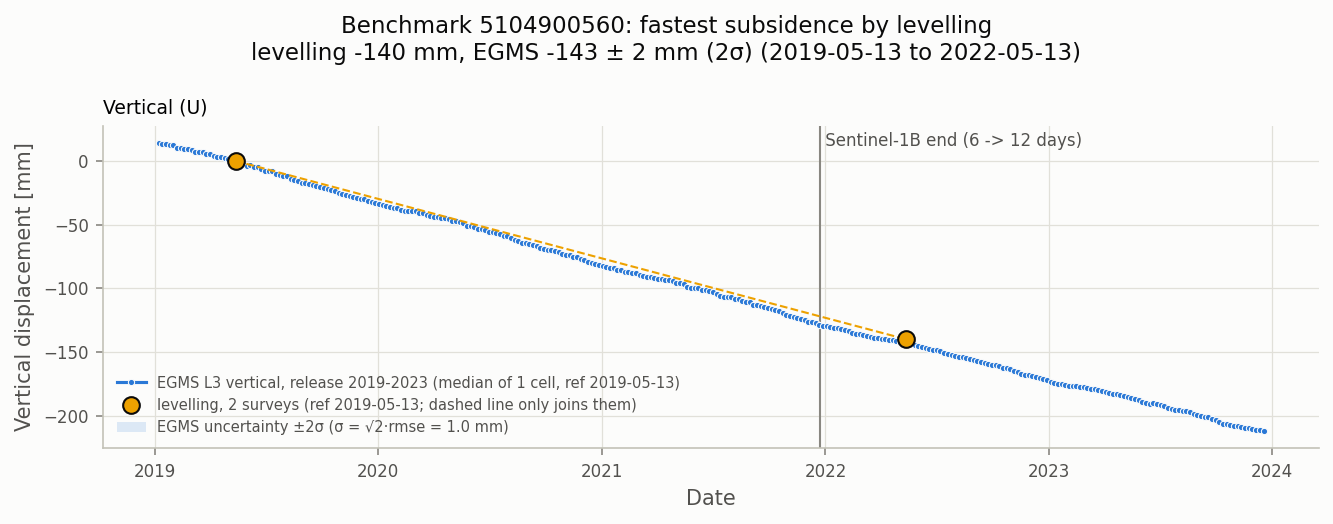

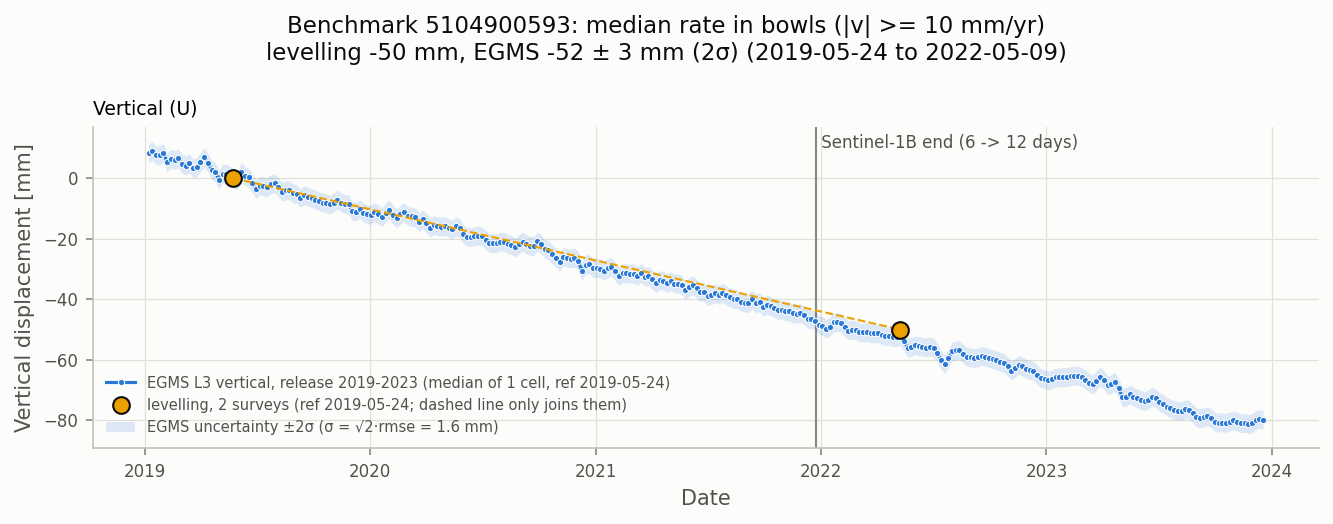

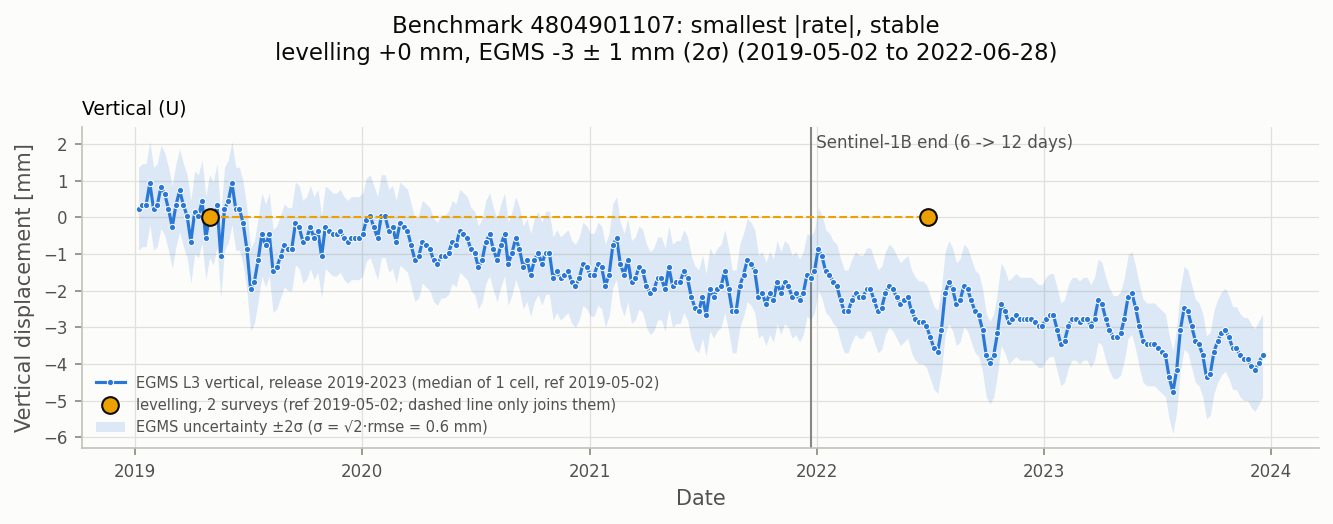

In [4]:
#@title Repery wybrane regułą: najszybsze osiadanie, mediana niecek, reper stabilny
przyklady = dict((lab, bid) for bid, lab in _levelling_check_examples(res, CHECK_CONFIG['monitoring']['example_rule'], strong))
for lab in ('fastest subsidence by levelling', f'median rate in bowls (|v| >= {strong:g} mm/yr)', 'smallest |rate|, stable'):
    if lab not in przyklady:
        print(f'Reguła „{lab}”: ten sam reper co na rycinie wyżej albo brak reperów w tej grupie')
        continue
    pokaz(C['figure'].parent / f"nrw_west_levelling_series_2019_2023_{przyklady[lab]}.png", 900)

**Jak czytać:** niebieska linia to EGMS co 6–12 dni, a jasnoniebieski pas wokół niej to niepewność EGMS (±2σ). Duże
żółte punkty to dwa pomiary niwelacyjne; przerywana linia tylko je łączy, między nimi niwelacji nie ma. Oba szeregi
zaczynają się od zera w dniu pierwszego pomiaru. Jeśli żółty punkt leży w pasie, EGMS i niwelacja zgadzają się
w granicach dokładności EGMS.

Na dwóch pierwszych reperach EGMS i niwelacja kończą się prawie w tym samym miejscu. Trzeci reper się nie rusza, a EGMS
pokazuje na nim kilka mm osiadania — wyjaśnia to następna sekcja.

## 4. Reper stabilny: czy różnica kilku mm to powód do niepokoju?

Niwelacja mówi, że reper się nie rusza, a EGMS pokazuje kilka mm osiadania w 3 lata. Rozkładamy to na dwie części:
**szum** (losowe skoki pomiaru, szary pas) i **wspólne przesunięcie** (to samo dla wszystkich reperów stabilnych).

- Reper **4804901107**: niwelacja **+0.0 mm**, EGMS **-3.1 ± 1.1 mm** (±2σ) w 3.16 roku.
- Wszystkie **307 reperów stabilnych** mają w EGMS wspólne tempo **-1.22 mm/rok**; przez ten czas daje to **-3.8 mm**.
- Po odjęciu wspólnego przesunięcia różnica EGMS − niwelacja wynosi **+0.8 mm** — **w granicach niepewności EGMS**.

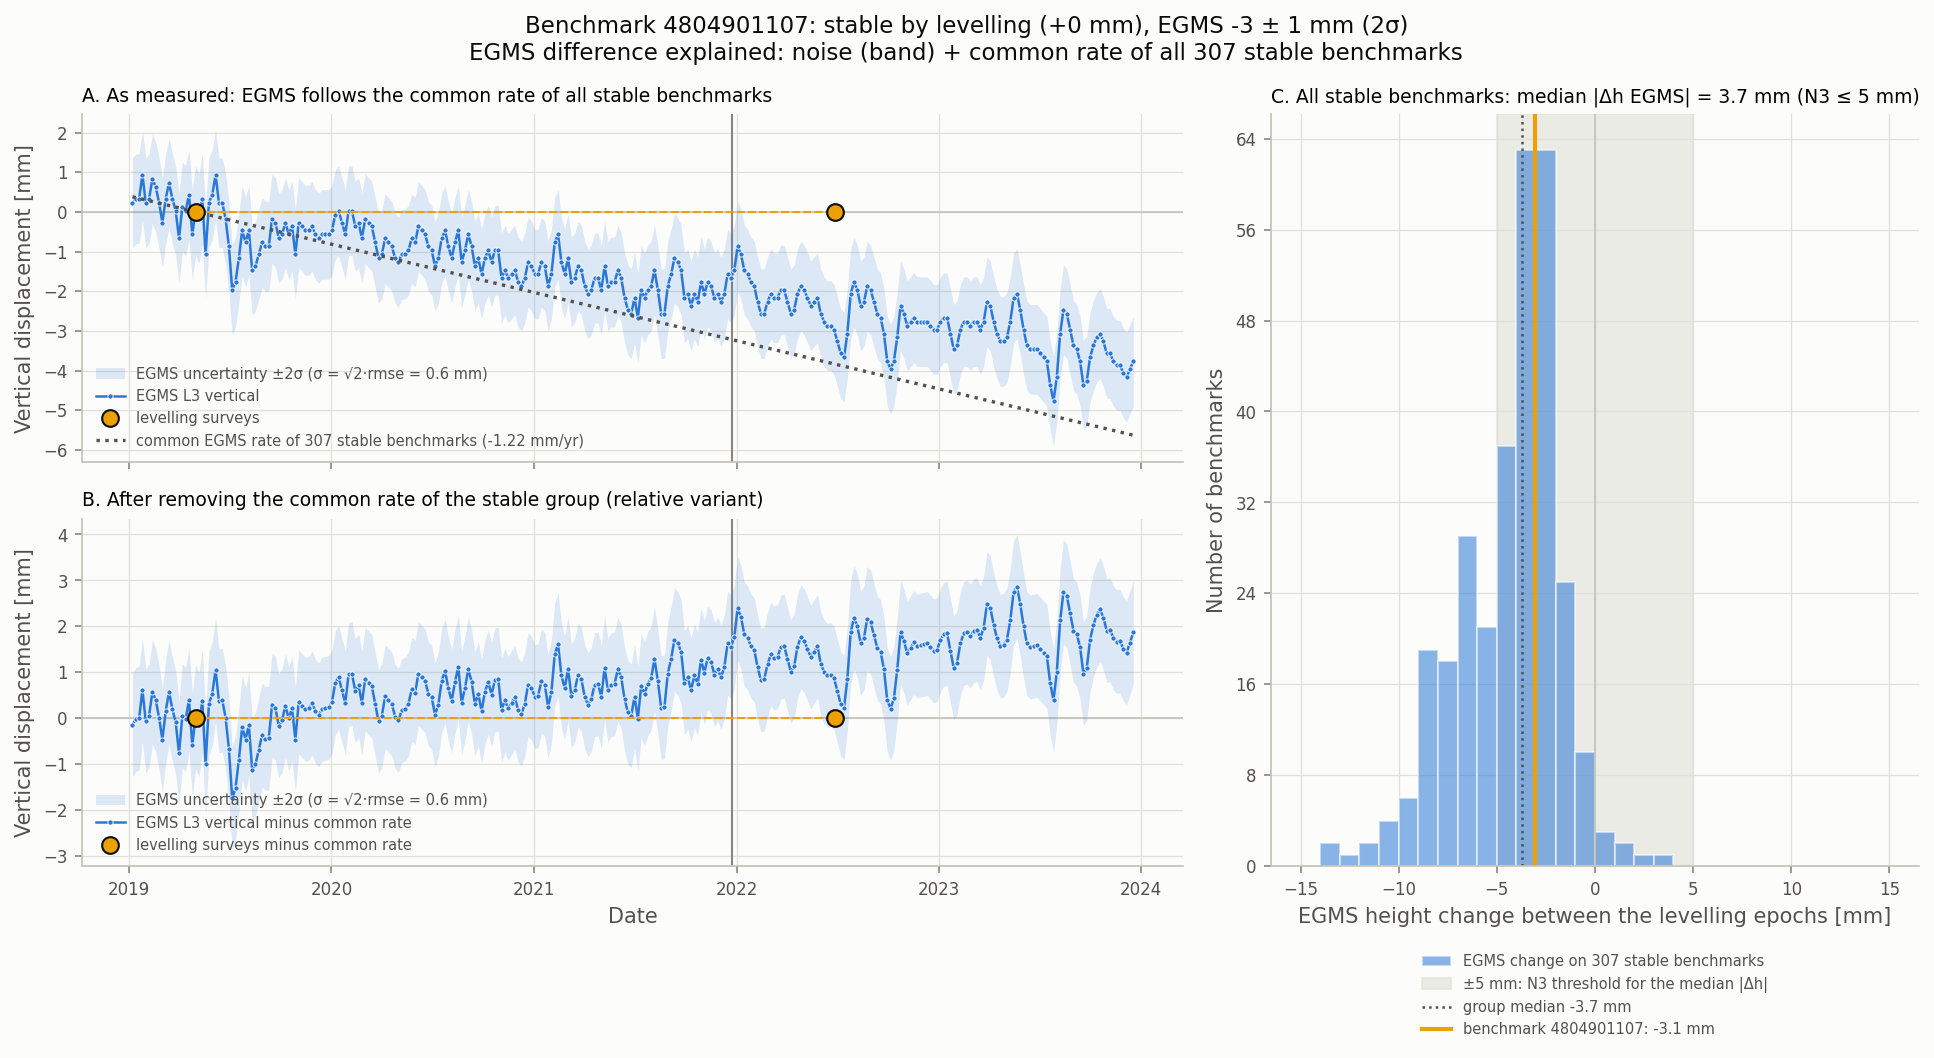

In [5]:
#@title Reper stabilny wybrany regułą: trzy panele i liczby
bid = przyklady.get('smallest |rate|, stable')
if bid is None:
    raise ValueError('Reguła nie wskazała reperu stabilnego (brak reperów o |v| bliskim zera)')
r = ok[ok['benchmark_id'] == bid].iloc[0]
wspolne = off['median_v_egms_group_mm_yr'] * r['dt_yr'] - off['median_v_lev_group_mm_yr'] * r['dt_yr']
po = r['diff_mm'] - wspolne
display(Markdown(
    f"- Reper **{bid}**: niwelacja **{r['dh_lev_mm']:+.1f} mm**, EGMS **{r['dh_egms_mm']:+.1f} ± {k * r['sigma_dh_mm']:.1f} mm** "
    f"(±{k:g}σ) w {r['dt_yr']:.2f} roku.\n"
    f"- Wszystkie **{off['n_group']} reperów stabilnych** mają w EGMS wspólne tempo **{off['offset_egms_minus_lev_mm_yr']:+.2f} mm/rok**; "
    f"przez ten czas daje to **{wspolne:+.1f} mm**.\n"
    f"- Po odjęciu wspólnego przesunięcia różnica EGMS − niwelacja wynosi **{po:+.1f} mm** — "
    + ('**w granicach niepewności EGMS**.' if abs(po) <= k * r['sigma_dh_mm'] else '**poza pasem niepewności EGMS**.')))
pokaz(C['figure'].parent / f"nrw_west_levelling_stable_2019_2023_{bid}.png", 1000)

**Jak czytać:**
- **Panel A (tak jak jest):** EGMS (niebieski) idzie wzdłuż kropkowanej linii, czyli wspólnego tempa wszystkich reperów
  stabilnych. Nie odjeżdża od niej, więc to nie jest ruch tego reperu.
- **Panel B (po odjęciu wspólnego tempa):** EGMS skacze wokół zera w pasie szumu, a pomiary niwelacyjne leżą w pasie.
  Po wyrównaniu „zera” obie metody pokazują to samo: reper się nie rusza.
- **Panel C (wszystkie repery stabilne):** zmiany EGMS na wszystkich reperach stabilnych skupiają się wokół kilku mm
  poniżej zera. Ten reper jest typowy. Kryterium N3, ustalone przed obliczeniami, dopuszcza medianę do 5 mm — jest
  spełnione.
- **Skala:** kilka mm wobec −140 mm w nieckach to kilka procent sygnału.

**Analogia:** mierzymy wzrost ludzi na promie. Miarka liczona od pokładu pokazuje, że nikt się nie zmienia. GPS liczony od
poziomu morza pokazuje, że wszyscy obniżają się o 1 mm na rok, bo cały prom powoli osiada. Obie miary są dobre, tylko mają
inne „zero”. Niwelacja liczy od reperów nawiązania sieci, a EGMS od układu ETRF2000 przez GNSS.

**Co jest pewne, a co jest hipotezą:** że przesunięcie jest wspólne dla wszystkich reperów stabilnych i mieści się
w progu — to zmierzyliśmy. Że jego przyczyną jest różne „zero” układów odniesienia — to najbardziej prawdopodobne
wyjaśnienie, ale go nie sprawdzaliśmy (Even i in. 2024 też go nie podają).

## 5. Ocena według kryteriów ustalonych przed obliczeniami

In [6]:
#@title Tabela kryteriów N1–N4: wariant główny i wariant względny
kody = ['N1', 'N2', 'N3', 'N4']
pytania = {'N1': 'N1: typowa różnica EGMS − niwelacja', 'N2': 'N2: zgodność kierunku ruchu',
           'N3': 'N3: repery stabilne bez fałszywego ruchu', 'N4': 'N4: przesunięcie tempa EGMS'}
g, w = kryteria(C['summary'], kody), kryteria(C['summary_rel'], kody)
# N3 w wariancie względnym nie jest liczone: repery stabilne są tam grupą odniesienia.
w.loc[(w['kod'] == 'N3') & (w['Spełnione'] == '— nie liczone'), 'Wynik'] = 'nie dotyczy (grupa odniesienia)'
t = g[['kod', 'Próg']].assign(Kryterium=g['kod'].map(pytania), **{
    'Wariant główny': g['Wynik'] + ' ' + g['Spełnione'].str[:1],
    'Względem reperów stabilnych': g['kod'].map(dict(zip(w['kod'], w['Wynik'] + ' ' + w['Spełnione'].str[:1])))})
tabela(t[['Kryterium', 'Próg', 'Wariant główny', 'Względem reperów stabilnych']])
display(Markdown(f"Przesunięcie EGMS względem niwelacji na {off['n_group']} reperach stabilnych: "
                 f"**{off['offset_egms_minus_lev_mm_yr']:+.2f} ± {off['offset_se_mm_yr']:.2f} mm/rok**"))

Kryterium,Próg,Wariant główny,Względem reperów stabilnych
N1: typowa różnica EGMS − niwelacja,<= 5.0 mm,6.0 mm ✘,3.4 mm ✔
N2: zgodność kierunku ruchu,>= 90%,77% reperów ✘,94% reperów ✔
N3: repery stabilne bez fałszywego ruchu,<= 5.0 mm,mediana |Δh_EGMS| 3.7 mm ✔,nie dotyczy (grupa odniesienia) —
N4: przesunięcie tempa EGMS,|bias| <= 1.5 mm/rok,mediana -1.97 mm/rok ✘,mediana -1.00 mm/rok ✔


Przesunięcie EGMS względem niwelacji na 307 reperach stabilnych: **-1.22 ± 0.05 mm/rok**

**Jak czytać:** ✔ = kryterium spełnione, ✘ = niespełnione, — = nie liczone.
- **Wariant główny** porównuje wartości wprost, tak jak Even i in. (2024). Nie spełnia progów N1, N2 i N4 przez stałe
  przesunięcie EGMS, a nie przez rozrzut.
- **Wariant względny** (dodatkowy) najpierw wyznacza wspólne „zero” na reperach, które według niwelacji się nie ruszają.
  Wtedy wszystkie liczone kryteria są spełnione. N3 nie jest tu liczone, bo te repery służą jako odniesienie.
- Wariant względny dodaliśmy po obejrzeniu wyniku głównego, więc werdykt główny się nie zmienia.

## 6. Niecki osiadania

In [7]:
#@title Repery w nieckach (tempo według niwelacji co najmniej 10 mm/rok) i pozostałe
gr, grw = pd.read_csv(C['groups']), pd.read_csv(C['groups_rel'])
for x in (gr, grw):     # kolejność wierszy z step_06.levelling_groups: wszystkie, niecki, pozostałe
    assert list(x['grupa'].str[:5]) == ['wszys', 'nieck', 'pozos'], list(x['grupa'])
tabela(pd.DataFrame({'Grupa': ['wszystkie', f'niecki (≥ {strong:g} mm/rok)', 'pozostałe'],
                     'Repery': gr['n'].astype(int),
                     'Typowa różnica [mm]': gr['median_abs_diff_mm'].round(1),
                     'Zgodność kierunku': (gr['sign_agreement'] * 100).round(0).astype('Int64').astype(str) + '%',
                     'Nachylenie (1 = ta sama skala)': gr['slope'].round(2),
                     'Najbliższa stacja GNSS [km, mediana]': gr['dist_station_km_median'].round(1)}))
display(Markdown(f"Po odniesieniu do reperów stabilnych typowa różnica w nieckach spada z "
                 f"**{gr['median_abs_diff_mm'].iat[1]:.1f} mm** do **{grw['median_abs_diff_mm'].iat[1]:.1f} mm**."))

Grupa,Repery,Typowa różnica [mm],Zgodność kierunku,Nachylenie (1 = ta sama skala),"Najbliższa stacja GNSS [km, mediana]"
wszystkie,1216,6.0,77%,0.96,10.7
niecki (≥ 10 mm/rok),54,5.1,100%,0.98,8.5
pozostałe,1162,6.0,75%,0.89,10.8


Po odniesieniu do reperów stabilnych typowa różnica w nieckach spada z **5.1 mm** do **2.6 mm**.

**Jak czytać:** w nieckach EGMS i niwelacja zgadzają się co do kierunku ruchu na każdym reperze, a skala ruchu jest
prawie 1:1. Niecki mają kilka kilometrów szerokości, a model GNSS do kalibracji EGMS ma siatkę około 50 km. Kalibracja
nie mogła ich więc „dorysować” — EGMS zmierzył je sam.

## 7. Największe rozbieżności

In [8]:
#@title Trzy największe różnice w nieckach (pokazujemy też to, co nie pasuje)
nie = ok[ok['v_lev_mm_yr'].abs() >= strong]
top = nie.reindex(nie['diff_mm'].abs().sort_values(ascending=False).index).head(3)
tabela(pd.DataFrame({'Reper': top['benchmark_id'], 'Niwelacja [mm]': top['dh_lev_mm'].round(1),
                     'EGMS [mm]': top['dh_egms_mm'].round(1), 'EGMS − niwelacja [mm]': top['diff_mm'].round(1),
                     f'Niepewność EGMS ±{k:g}σ [mm]': (k * top['sigma_dh_mm']).round(1),
                     'Co to znaczy': top['diff_mm'].map(lambda d: 'EGMS: mniej osiadania' if d > 0 else 'EGMS: więcej osiadania')}))

Reper,Niwelacja [mm],EGMS [mm],EGMS − niwelacja [mm],Niepewność EGMS ±2σ [mm],Co to znaczy
5104900368,-84.0,-60.5,23.5,8.5,EGMS: mniej osiadania
5104900601,-73.0,-87.4,-14.4,1.7,EGMS: więcej osiadania
5104900095,-128.0,-141.2,-13.2,2.0,EGMS: więcej osiadania


**Jak czytać:** we wszystkich trzech kierunek ruchu się zgadza. Część różnic „więcej osiadania” to ogólne przesunięcie
EGMS (kilka mm w 3 lata). Reper z dużą dodatnią różnicą odstaje naprawdę; prawdopodobna przyczyna (niesprawdzona) to
reper na brzegu niecki, gdzie komórka 100 × 100 m uśrednia teren osiadający szybciej i wolniej.

## Najważniejsze liczby

In [9]:
#@title Podsumowanie liczbowe (czytane z plików wyników)
sm = pd.read_csv(C['summary'])
nach = sm.loc[sm['kryterium'].str.startswith('Nachylenie'), 'wynik'].iat[0].split(',')[0]
szyb = ok.sort_values('v_lev_mm_yr').iloc[0]
display(Markdown(
    f"- **{len(ok)} reperów** porównanych; zmiana wysokości z EGMS idzie prawie 1:1 z niwelacją (nachylenie {nach}).\n"
    f"- **Niecki ({int(gr['n'].iat[1])} reperów):** kierunek ruchu zgodny w {gr['sign_agreement'].iat[1]:.0%}, "
    f"nachylenie {gr['slope'].iat[1]:.2f}.\n"
    f"- **Najszybciej osiadający reper {szyb['benchmark_id']}:** niwelacja {szyb['dh_lev_mm']:+.0f} mm, "
    f"EGMS {szyb['dh_egms_mm']:+.0f} mm.\n"
    f"- **Przesunięcie EGMS:** {off['offset_egms_minus_lev_mm_yr']:+.2f} mm/rok względem reperów stabilnych.\n"
    f"- **Niepewność EGMS** (mediana, ±{k:g}σ): ±{k * unc['median_sigma_dh_mm']:.1f} mm; w granicach niepewności "
    f"{unc['share_within_absolute']:.0%} reperów (po odjęciu wspólnego przesunięcia {unc['share_within_relative']:.0%})."))

- **1216 reperów** porównanych; zmiana wysokości z EGMS idzie prawie 1:1 z niwelacją (nachylenie 0.96).
- **Niecki (54 reperów):** kierunek ruchu zgodny w 100%, nachylenie 0.98.
- **Najszybciej osiadający reper 5104900560:** niwelacja -140 mm, EGMS -143 mm.
- **Przesunięcie EGMS:** -1.22 mm/rok względem reperów stabilnych.
- **Niepewność EGMS** (mediana, ±2σ): ±2.0 mm; w granicach niepewności 12% reperów (po odjęciu wspólnego przesunięcia 37%).

## Wniosek

- **Niwelacja, pomiar niezależny od GNSS, potwierdza osiadanie widoczne w EGMS:** to samo położenie niecek, ten sam
  kierunek ruchu i prawie ta sama skala.
- **EGMS mierzy ruch sam,** nie tylko powtarza kalibrację GNSS: niecki są dużo mniejsze niż siatka modelu kalibracji.
- **Poziom bezwzględny wymaga ostrożności:** EGMS ma przesunięcie około 1–2 mm/rok. Przy ruchu poniżej ~2 mm/rok i przy
  wysokościach bezwzględnych potrzebny jest punkt odniesienia z pomiaru naziemnego.
- EGMS jest produktem archiwalnym, aktualizowanym raz w roku; nie wykrywa zdarzeń nagłych.

**Czego tu nie ma:** porównania z GNSS w NRW (w obszarze nie ma osiadającej stacji — wynik nierozstrzygnięty),
krzywych „czasu do wykrycia” (metoda wymaga poprawki) i własnego przetwarzania Sentinel-1 (nieuruchomione). Szczegóły:
`EGMS_Monitoring.ipynb` i `docs/evidence/F10_NRW_niwelacja_EGMS.md`.

**Źródła:** EGMS (Copernicus Land Monitoring Service); niwelacja: Geobasis NRW; porównanie z niwelacją w NRW: Even,
Westerhaus, Kutterer (2024), PFG 92:253–270; progi: Koudogbo i in. (2025) EGMS Validation Report.